# Archetypal analysis of clonal embeddings

Clustering works well when clones fall into separate groups. Clonal embeddings can be continuous, though, for three reasons:

1. clones can differ by **gradual** shifts in cell type proportions;
2. the borders between cell types themselves can be blurry;
3. small clones are placed less precisely, which smears the borders between groups.

Including only large clones helps with the third reason, and a better cell representation (e.g. `Concord` instead of plain PCA) can help with the second. But often the variation is genuinely continuous, and any clustering would draw arbitrary borders through it.

**Archetypal analysis** describes such data without borders. It finds a few **archetypes**, the extreme behaviours at the corners of the data cloud, and describes every clone as a **mixture** of them: a set of non-negative weights that sum to one. A clone with weights (0.7, 0.3, 0) is "mostly archetype 0, partly archetype 1".

**Why this fits clone2vec well.** In a clonal embedding, a clone that mixes two behaviours sits between the clones showing each behaviour alone. So "corners and mixtures of corners" is a natural description of the clonal space.

We use the `partipy` package on CD8 T cell clones from the Liu et al. NSCLC cohort, where clones are defined by T cell receptor sequences.

**The plan:**

1. Load the data.
2. Choose the number of archetypes.
3. Compute each clone's archetype weights.
4. Turn weights into groups when needed.
5. Find genes associated with each archetype.

## Setup

In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import clone2vec as c2v
import partipy as pt

sc.set_figure_params(dpi=80)
sc.settings.verbosity = 3
sns.set_style("ticks")

## Step 1: Load the data

We load both the cell-level object (for expression) and the clone-level object with a precomputed clone2vec embedding.

In [2]:
adata = c2v.datasets.Liu_NSCLC_CD8(embedding_type="gex")
clones = c2v.datasets.Liu_NSCLC_CD8(embedding_type="c2v")

using gene expression embedding
using clonal embedding (compositions in adata.X)


## Step 2: Choose the number of archetypes

Just as with the number of clusters, there is no single right answer, so we look at three complementary criteria for 2 to 8 archetypes:

1. **Variance explained:** how much of the embedding the archetypes reproduce. More archetypes always explain more, so we look for an elbow, where adding one more stops paying off.
2. **Information criterion:** fit quality penalized by the number of archetypes. Lower is better.
3. **Bootstrap stability:** refit on resampled clones and measure how much the archetype positions move. Real archetypes stay put.

We fit archetypes in the first 10 dimensions of `clone2vec`.

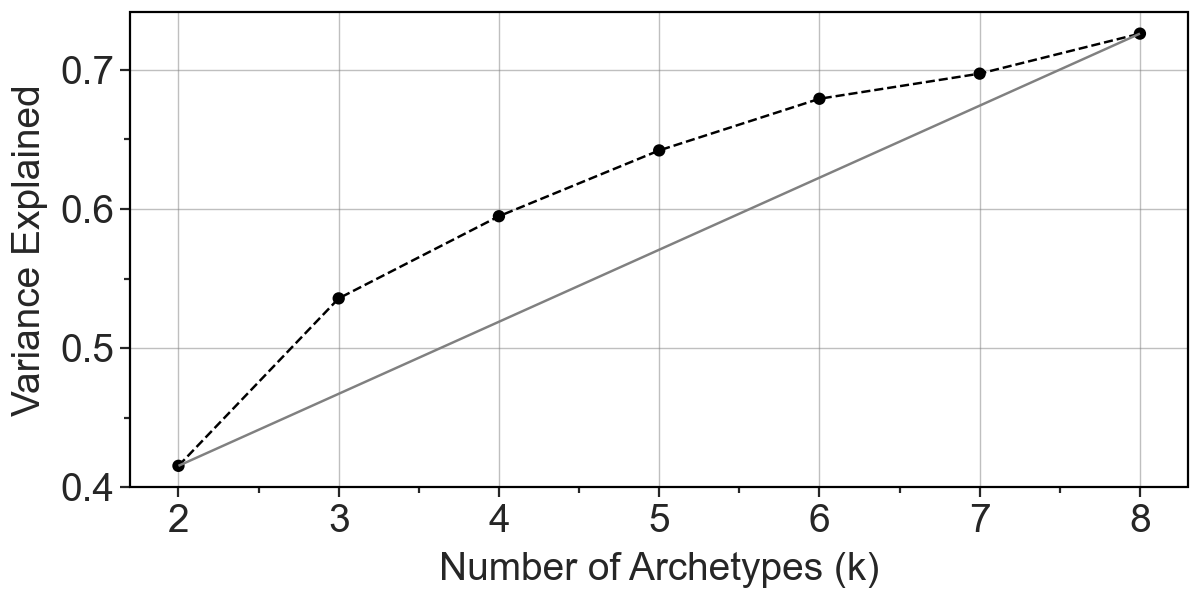

In [3]:
pt.set_obsm(adata=clones, obsm_key="clone2vec", n_dimensions=10)
pt.compute_selection_metrics(adata=clones, n_archetypes_list=range(2, 9))
pt.plot_var_explained(clones)

**Variance explained:** the largest gain comes from going from 2 to 3 archetypes. After that, the curve flattens.

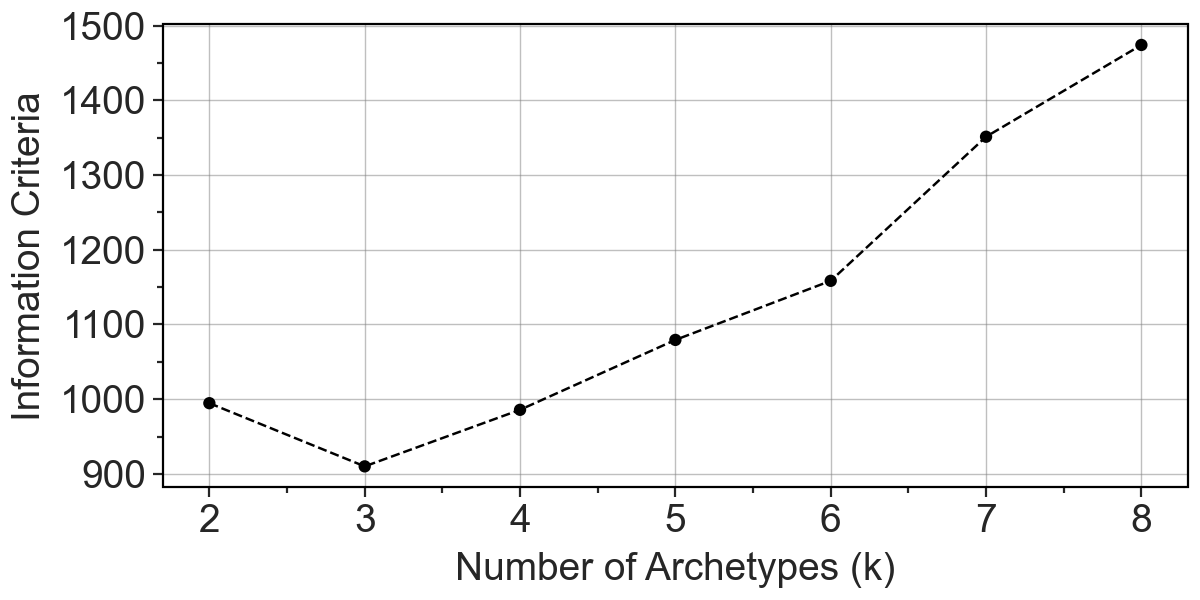

In [4]:
pt.plot_IC(clones)

**Information criterion:** a clear minimum at 3 archetypes.

In [5]:
pt.compute_bootstrap_variance(
    adata=clones,
    n_bootstrap=100,
    n_archetypes_list=range(2, 9),
    verbose=True,
)

Testing 8 Archetypes: 100%|██████████| 100/100 [00:00<00:00, 243.42it/s]


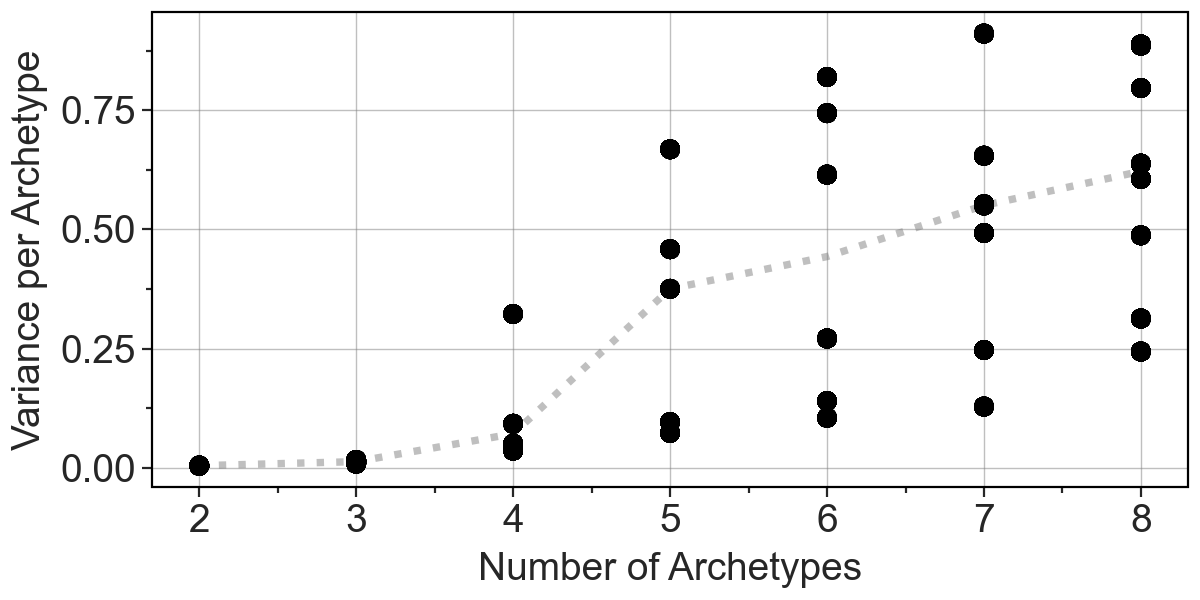

In [6]:
pt.plot_bootstrap_variance(clones, summary_method="median")

**Bootstrap stability:** with 2 or 3 archetypes, their positions barely change between resamples. From 4 to 5 archetypes onwards, some of them start moving a lot, a sign that they fit noise rather than real extremes.

All three criteria point to **three archetypes**.

## Step 3: Archetype weights of every clone

`pt.get_aa_result(...)["A"]` returns a clones × archetypes matrix of weights. We store it in `clones.obsm["X_AA"]` and plot each column on the clonal UMAP.

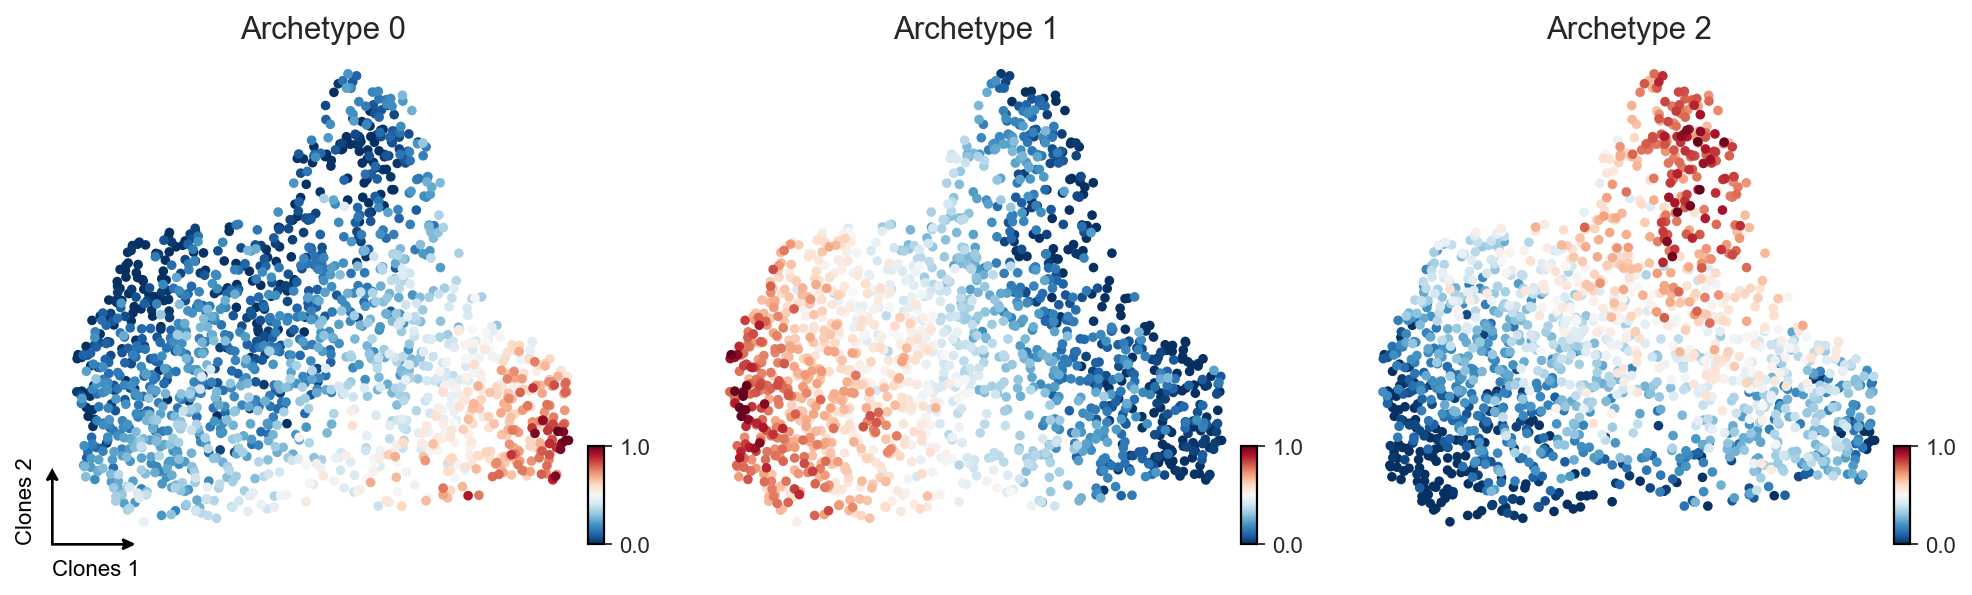

In [7]:
clones.obsm["X_AA"] = pt.get_aa_result(clones, n_archetypes=3)["A"]

axes = c2v.pl.embedding(clones, obsm_name="X_AA", obsm_component=[0, 1, 2],
                        frameon=False, show=False, cmap="RdBu_r",
                        title=["Archetype 0", "Archetype 1", "Archetype 2"])

c2v.pl.embedding_axis(axes[0], label="Clones")
c2v.pl.small_cbar(axes)

**What to look for:** each archetype owns one corner of the clonal map (lower right, left, top), and its weight fades **gradually** towards the other corners. This is the continuum that clustering would have to cut through.

## Step 4: From weights to groups

Sometimes discrete groups are still handy, for plotting or for comparing metadata. Two ways to get them from the weights:

* **Hard assignment:** every clone goes to the archetype with the largest weight.
* **Soft assignment:** a clone is assigned only if one archetype has at least 50% of its weight (`confidence_level = 0.5`). Mixed clones stay unassigned (grey).

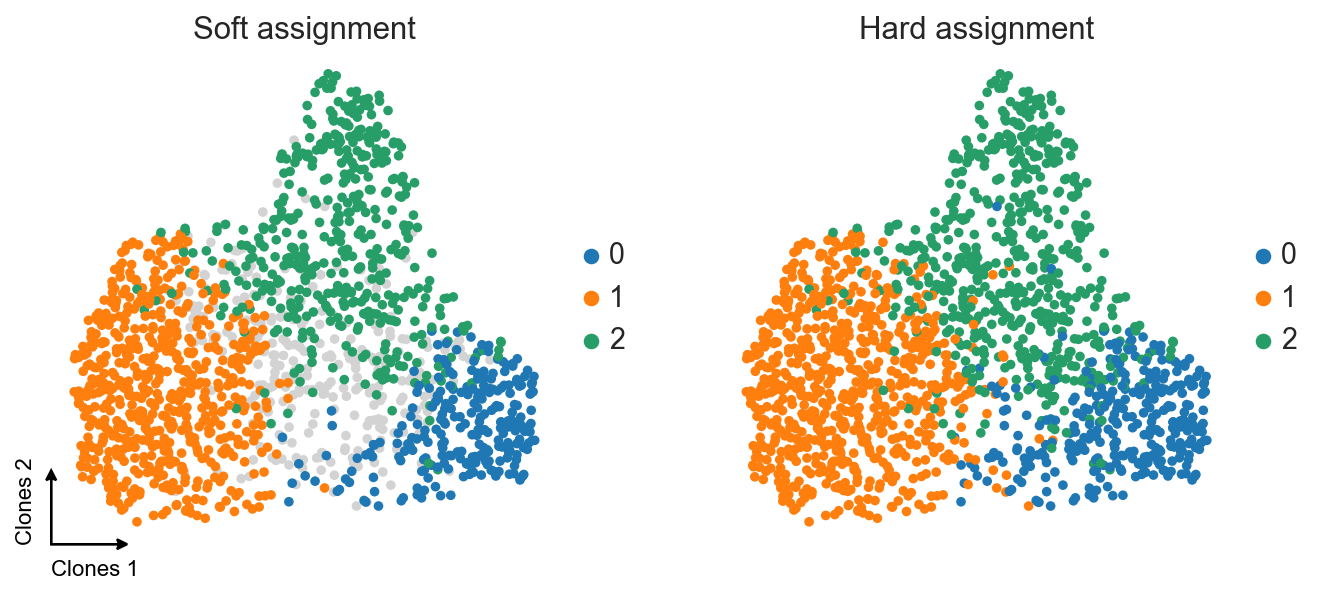

In [8]:
confidence_level = 0.5

clones.obs["AA_hard"] = np.argmax(clones.obsm["X_AA"], axis=1)
clones.obs["AA_soft"] = [
    clones.obs["AA_hard"].iloc[i] if j > 0 else -1
    for i, j in enumerate((clones.obsm["X_AA"] >= confidence_level).sum(axis=1))
]

clones.obs["AA_hard"] = clones.obs["AA_hard"].astype("category")
clones.obs["AA_soft"] = clones.obs["AA_soft"].astype("category")

axes = sc.pl.umap(
    clones,
    color=["AA_soft", "AA_hard"],
    palette={
        -1: "lightgrey",
        0: sns.color_palette()[0],
        1: sns.color_palette()[1],
        2: sns.color_palette()[2],
    },
    title=["Soft assignment", "Hard assignment"],
    frameon=False,
    groups=[0, 1, 2],
    na_in_legend=False,
    show=False,
)
c2v.pl.embedding_axis(axes[0], label="Clones")

**What to look for:** soft assignment leaves a grey band of mixed clones between the three corners. With hard assignment, these clones are forced into one archetype or another, and they blur the comparison between groups. Use soft assignment when you want clean, typical examples of each behaviour.

## Step 5: Genes associated with each archetype

Weights are continuous, so instead of a differential expression test between hard groups we can **correlate** each gene with each archetype weight across all clones. Mixed clones then contribute in proportion to how much of each archetype they carry, instead of being forced into one group.

First, `c2v.pp.transfer_expression` computes the average expression of each clone over its cells.

In [9]:
clones = c2v.pp.transfer_expression(adata, clones)

summarizing expression at clone level: 
    using `adata.X` as expression source
    finished (0:00:07): created clone-level AnnData with
     .X aggregated expression matrix (clones × genes)
     .uns['transfer_expression'] dict with 'strategy'
     .uns['mask_key'] string with obsm key for boolean mask of clones with non-zero cells
     .obsm['counts'] dataframe of features
     .obsm['proportions'] dataframe of features


Then `c2v.tl.associations` correlates every gene with every column of `clones.obsm["X_AA"]` and stores correlations, slopes and adjusted p-values in `clones.varm`.

In [10]:
c2v.tl.associations(clones, response_key="X_AA")

computing feature–response associations: 
    using `adata.X` as features
    using `adata.obsm['X_AA']` as response
    computed 'pearson' statistics for 'X' features
    finished (0:00:01): added
     .varm['<response_key>:<feature matrix>:pearson:r'] matrix with correlation coefficients
     .varm['<response_key>:<feature matrix>:pearson:pvalue'] matrix with uncorrected p-values
     .varm['<response_key>:<feature matrix>:pearson:slope'] matrix with regression slopes coefficients
     .varm['<response_key>:<feature matrix>:pearson:p_adj'] matrix with corrected p-values


In [11]:
print(
    "Archetype 0 correlations:",
    clones.varm["X_AA:X:pearson:r"]["X_AA:0"].dropna().sort_values(ascending=False).head(5),
    "", "Archetype 1 correlations:",
    clones.varm["X_AA:X:pearson:r"]["X_AA:1"].dropna().sort_values(ascending=False).head(5),
    "", "Archetype 2 correlations:",
    clones.varm["X_AA:X:pearson:r"]["X_AA:2"].dropna().sort_values(ascending=False).head(5),
    sep="\n",
)

Archetype 0 correlations:
CXCL13    0.674131
LAYN      0.672333
CTLA4     0.668017
HAVCR2    0.666067
ENTPD1    0.654256
Name: X_AA:0, dtype: float64

Archetype 1 correlations:
GZMK     0.814815
CST7     0.585591
CMC1     0.573601
RPL28    0.541970
KLRG1    0.509160
Name: X_AA:1, dtype: float64

Archetype 2 correlations:
S100A4    0.585500
HOPX      0.563047
S100A6    0.491612
ZNF683    0.487993
IL7R      0.434046
Name: X_AA:2, dtype: float64


**What to look for:** each archetype has a recognizable program:

* **Archetype 0:** CXCL13, LAYN, CTLA4, HAVCR2 (TIM-3), ENTPD1 (CD39). This is the exhaustion program of chronically stimulated, tumour-reactive T cells.
* **Archetype 1:** GZMK, CST7, CMC1, KLRG1. This is a GZMK+ effector-memory program.
* **Archetype 2:** S100A4, HOPX, ZNF683, IL7R. This is a tissue-resident memory–like program.

These are three of the four CD8 T cell clonal archetypes described in the clone2vec manuscript (CXCL13<sup>High</sup>, GZMK<sup>High</sup> and IL7R<sup>High</sup>), recovered here from one cohort, without any cell type labels.